# Brazil: well-level production from ANP

ANP publishes monthly production for every Brazilian well. `fetch` grabs the
bulk zips from gov.br — yearly archives for 2005–2020, monthly ones for
2021–2023 (from 2024 on the data only exists in ANP's interactive
[CDP app](https://cdp.anp.gov.br/), so `fetch` raises a pointed error).

One month arrives as **three CSVs**: terra (onshore), mar (offshore) and
pré-sal — and the pré-sal file is a *subset* of mar, which matters below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ogprod

# Categorical palette in fixed slot order (colorblind-safe adjacency)
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "figure.figsize": (9, 4),
    "font.size": 11,
})

DATA = Path("../data")
DATA.mkdir(exist_ok=True)

In [2]:
paths = ogprod.fetch("anp", DATA / "anp", year=2023, month=6)
[p.name for p in paths]

['2023_06_producao_Mar.csv',
 '2023_06_producao_Presal.csv',
 '2023_06_producao_Terra.csv']

In [3]:
parts = {p.name.rsplit("_", 1)[-1].removesuffix(".csv").lower(): ogprod.load("anp", p)
         for p in paths}
# Country totals = terra + mar only: the pré-sal wells are already in mar
brazil = pd.concat([parts["terra"], parts["mar"]], ignore_index=True)
brazil.head()

,source,entity_type,entity_id,entity_name,field,basin,region,operator,period,product,volume
0,anp,well,7-ET-660-RN,7-ET-660-RN,ESTREITO,Potiguar,Rio Grande do Norte,3R Potiguar,2023-06-01,oil,6.478096
1,anp,well,1-LP-1-BA,1-LP-1-BA,LAGOA DO PAULO,Recôncavo,Bahia,Recôncavo E&P,2023-06-01,oil,86.558089
2,anp,well,7-FP-83-RN,7-FP-83-RN,FAZENDA POCINHO,Potiguar,Rio Grande do Norte,3R Potiguar,2023-06-01,oil,7.577970
3,anp,well,3-LP-3-BA,3-LP-3-BA,LAGOA DO PAULO,Recôncavo,Bahia,Recôncavo E&P,2023-06-01,oil,30.342884
4,anp,well,7-ET-665-RN,7-ET-665-RN,ESTREITO,Potiguar,Rio Grande do Norte,3R Potiguar,2023-06-01,oil,13.220906


## Pré-sal is a subset of mar — don't sum all three

Concatenating every CSV in the zip double-counts pre-salt wells. The overlap is
most of the offshore barrels:

In [4]:
BBL_D = lambda v: ogprod.convert(v, "m3", "bbl") / 30 / 1e6  # June has 30 days

oil = {name: part[part["product"] == "oil"]["volume"].sum() for name, part in parts.items()}
for name in ("terra", "mar", "presal"):
    print(f"{name:>7}: {BBL_D(oil[name]):.2f} M bbl/d")
print(f"\nBrazil total (terra + mar):    {BBL_D(oil['terra'] + oil['mar']):.2f} M bbl/d")
print(f"pré-sal share of offshore oil: {oil['presal'] / oil['mar']:.0%}")

  terra: 0.07 M bbl/d
    mar: 3.29 M bbl/d
 presal: 2.55 M bbl/d

Brazil total (terra + mar):    3.36 M bbl/d
pré-sal share of offshore oil: 78%


## Where the oil comes from

A ranked horizontal bar wants a single hue — magnitude is the message, the
axis carries the values.

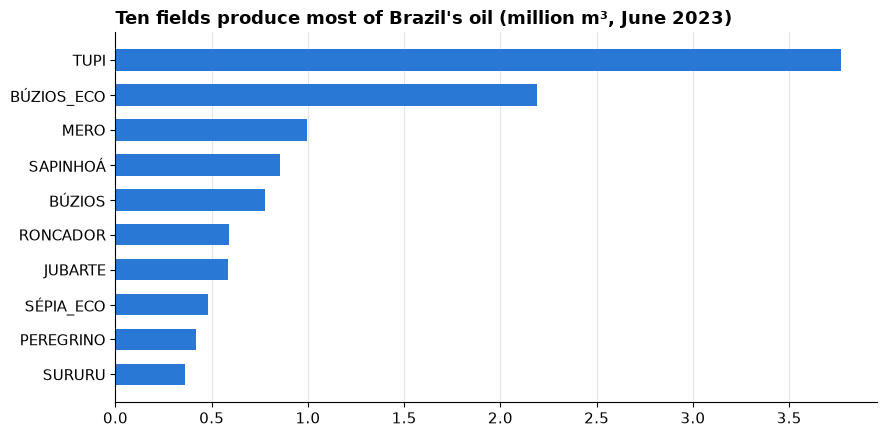

In [5]:
top = (brazil[brazil["product"] == "oil"]
       .groupby("field")["volume"].sum()
       .nlargest(10)
       .sort_values())

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top.values / 1e6, color=PALETTE[0], height=0.62)
ax.set_title("Ten fields produce most of Brazil's oil (million m³, June 2023)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

Well-level granularity means you can go as fine as a single wellbore:

In [6]:
tupi = brazil[(brazil["field"] == "TUPI") & (brazil["product"] == "oil")]
print(f"TUPI: {len(tupi)} producing wells, "
      f"best well {BBL_D(tupi['volume'].max()) * 1e3:.1f} k bbl/d, "
      f"median {BBL_D(tupi['volume'].median()) * 1e3:.1f} k bbl/d")
tupi.nlargest(5, "volume")[["entity_id", "field", "basin", "volume"]]

TUPI: 58 producing wells, best well 31.4 k bbl/d, median 15.0 k bbl/d


,entity_id,field,basin,volume
25026,7-TUP-121DA-RJS,TUPI,Santos,149552.954824
25030,9-LL-20D-RJS,TUPI,Santos,136062.251511
25018,9-LL-12D-RJS,TUPI,Santos,115968.468786
25064,8-LL-87D-RJS,TUPI,Santos,107939.735992
25276,7-LL-66-RJS,TUPI,Santos,106493.483103
